# Gauteng SEIHR implementation

#  Data preparation and observations



In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.integrate import cumulative_trapezoid
import torch
import torch.nn as nn


csv_path = Path("Gauteng_DATCOV_weekly_modelling_data.csv")

if not csv_path.exists():
    csv_path = Path("/mnt/data/Gauteng_DATCOV_weekly_modelling_data.csv")

data = pd.read_csv(csv_path)

assert len(data) == 146
assert np.array_equal(data["t"].to_numpy(), np.arange(146))
data["day"] = 7 * data["t"]


print(data[["t", "epi_week", "total_admissions"]].head())
print("Digitised total:", round(data["total_admissions"].sum(), 2))

   t  epi_week  total_admissions
0  0  2020-W10          0.000000
1  1  2020-W11         11.893500
2  2  2020-W12         17.409921
3  3  2020-W13         26.223487
4  4  2020-W14         39.064704
Digitised total: 162128.34


## Plot the actual digitised observations



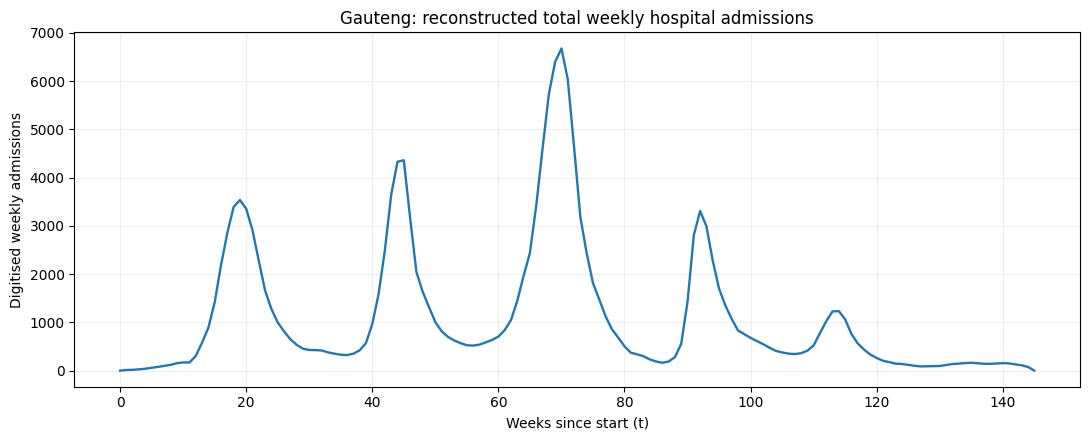

In [2]:
plt.figure(figsize=(11, 4.5))

plt.plot(
    data["t"],
    data["total_admissions"],
    lw=1.7
)

plt.xlabel("Weeks since start (t)")
plt.ylabel("Digitised weekly admissions")
plt.title("Gauteng: reconstructed total weekly hospital admissions")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# **PINN creation:**

# **Build initial neural network**

In [3]:
# Modelling time horizon in days
T_days = 7.0 * len(data)

print(f"Model horizon: {T_days:.1f} days")

Model horizon: 1022.0 days


In [4]:
# ============================================================
# Physically consistent SEIHR PINN
# ===========================================================

torch.manual_seed(42)


class MonotoneCurve(nn.Module):
    """
    Differentiable monotone function F(t):
        F(0) = 0
        F(T_days) = 1
        F'(t) >= 0
    """

    def __init__(self, K=16):
        super().__init__()

        self.raw_weights = nn.Parameter(
            torch.zeros(K)
        )

        self.raw_slopes = nn.Parameter(
            torch.zeros(K)
        )

        centers = torch.linspace(
            0.04 * T_days,
            0.96 * T_days,
            K
        )

        self.register_buffer(
            "centers",
            centers.reshape(1, -1)
        )

    def forward(self, t):

        # Positive weights that sum to 1
        weights = torch.softmax(
            self.raw_weights,
            dim=0
        ).reshape(1, -1)

        # Positive slopes
        slopes = (
            0.005
            + 0.095 * torch.sigmoid(
                self.raw_slopes
            )
        ).reshape(1, -1)

        c = self.centers

        z = torch.sigmoid(
            slopes * (t - c)
        )

        z0 = torch.sigmoid(
            slopes * (0.0 - c)
        )

        zT = torch.sigmoid(
            slopes * (T_days - c)
        )

        basis = (
            (z - z0)
            / (zT - z0 + 1e-8)
        )

        return torch.sum(
            weights * basis,
            dim=1,
            keepdim=True
        )


class SEIHR_PINN(nn.Module):

    def __init__(self, hidden=64, depth=4, K=16):
        super().__init__()

        layers = [
            nn.Linear(1, hidden),
            nn.Tanh()
        ]

        for _ in range(depth - 1):
            layers += [
                nn.Linear(hidden, hidden),
                nn.Tanh()
            ]

        # Distribution among S, E, I, H
        layers += [nn.Linear(hidden, 4)]

        self.net = nn.Sequential(*layers)

        # Cumulative recovered trajectory
        self.R_curve = MonotoneCurve(K)

        # Cumulative loss from living population
        self.D_curve = MonotoneCurve(K)

        # Determines eventual proportions:
        # remaining living population / recovered / deaths
        self.removal_logits = nn.Parameter(
            torch.tensor([3.0, 0.0, -3.0])
        )

        # Start network strongly susceptible
        with torch.no_grad():

            self.net[-1].weight.normal_(
                mean=0.0,
                std=0.01
            )

            self.net[-1].bias.copy_(
                torch.tensor([
                    6.0,   # S
                   -5.0,   # E
                   -5.0,   # I
                   -9.0    # H
                ])
            )

    def forward(self, t):

    # ---------------------------------------------------
    # Scale time to [-1, 1]
    # ---------------------------------------------------

        t_scaled = 2.0 * t / T_days - 1.0

        raw = self.net(t_scaled)

    # Neural-network distribution among S, E, I, H
        learned_proportions = torch.softmax(
            raw,
            dim=1
        )

    # ---------------------------------------------------
    # EXACT initial distribution
    #
    # At t = 0:
    # S = (N0 - 1)/N0
    # E = 0
    # I = 1/N0
    # H = 0
    # ---------------------------------------------------

        initial_proportions = torch.tensor(
            [
                (N0 - 1.0) / N0,
                0.0,
                1.0 / N0,
                0.0
            ],
            dtype=t.dtype,
            device=t.device
        ).reshape(1, 4)

        # Smooth transition away from the fixed initial state.
        # g(0) = 0 exactly.
        g = 1.0 - torch.exp(-t / 7.0)

        active_proportions = (
            (1.0 - g) * initial_proportions
            + g * learned_proportions
        )

        # ---------------------------------------------------
        # Monotone recovered population
        # ---------------------------------------------------

        amplitudes = torch.softmax(
            self.removal_logits,
            dim=0
        )

        R_final = amplitudes[1]
        D_final = amplitudes[2]

        R = R_final * self.R_curve(t)

        # D is cumulative mortality/loss from the
        # living SEIHR population
        D = D_final * self.D_curve(t)

        # ---------------------------------------------------
        # Living population
        # ---------------------------------------------------

        N_living = 1.0 - D

        # Population remaining in S,E,I,H
        active_population = N_living - R

        active_states = (
            active_population
            * active_proportions
        )

        S = active_states[:, 0:1]
        E = active_states[:, 1:2]
        I = active_states[:, 2:3]
        H = active_states[:, 3:4]

        return torch.cat(
            [S, E, I, H, R],
            dim=1
        )


model = SEIHR_PINN()

print(model)

SEIHR_PINN(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=4, bias=True)
  )
  (R_curve): MonotoneCurve()
  (D_curve): MonotoneCurve()
)


In [5]:
# ============================================================
# Fixed initial conditions
# ============================================================

N0 = 15_500_000

S0 = (N0 - 1) / N0
E0 = 0.0
I0 = 1.0 / N0
H0 = 0.0
R0 = 0.0

Y0_target = torch.tensor(
    [S0, E0, I0, H0, R0],
    dtype=torch.float32
)

print("Fixed initial compartment fractions:")
print(f"S0 = {S0:.10f}")
print(f"E0 = {E0:.10f}")
print(f"I0 = {I0:.10f}")
print(f"H0 = {H0:.10f}")
print(f"R0 = {R0:.10f}")

Fixed initial compartment fractions:
S0 = 0.9999999355
E0 = 0.0000000000
I0 = 0.0000000645
H0 = 0.0000000000
R0 = 0.0000000000


In [6]:
# ============================================================
# Trainable epidemiological parameters
# ============================================================

class EpidemiologicalParameters(nn.Module):
    """
    Trainable SEIHR parameters.

    Each parameter is constrained to a biologically/plausibly
    chosen interval using a sigmoid transformation.
    """

    def __init__(self):
        super().__init__()

        # Raw unconstrained parameters
        self.raw_sigma   = nn.Parameter(torch.tensor(0.0))
        self.raw_gamma   = nn.Parameter(torch.tensor(0.0))
        self.raw_eta     = nn.Parameter(torch.tensor(0.0))
        self.raw_gamma_H = nn.Parameter(torch.tensor(0.0))
        self.raw_d_I     = nn.Parameter(torch.tensor(0.0))
        self.raw_d_H     = nn.Parameter(torch.tensor(0.0))

    @staticmethod
    def bounded(raw, lower, upper):
        return lower + (upper - lower) * torch.sigmoid(raw)

    def forward(self):

        # Literature-supported range already selected
        sigma = self.bounded(
            self.raw_sigma,
            0.20,
            0.33
        )

        # Broad optimisation bounds for now.
        # These can be refined after identifiability/sensitivity analysis.
        gamma = self.bounded(
            self.raw_gamma,
            0.05,
            0.25
        )

        eta = self.bounded(
            self.raw_eta,
            0.001,
            0.10
        )

        gamma_H = self.bounded(
            self.raw_gamma_H,
            0.03,
            0.25
        )

        d_I = self.bounded(
            self.raw_d_I,
            0.0001,
            0.03
        )

        d_H = self.bounded(
            self.raw_d_H,
            0.001,
            0.15
        )

        return {
            "sigma": sigma,
            "gamma": gamma,
            "eta": eta,
            "gamma_H": gamma_H,
            "d_I": d_I,
            "d_H": d_H
        }


epi_params = EpidemiologicalParameters()


# ------------------------------------------------------------
# Check starting values
# ------------------------------------------------------------

pars = epi_params()

print("Initial trainable parameter values:")
for name, value in pars.items():
    print(f"{name:8s} = {value.item():.6f} day^-1")

Initial trainable parameter values:
sigma    = 0.265000 day^-1
gamma    = 0.150000 day^-1
eta      = 0.050500 day^-1
gamma_H  = 0.140000 day^-1
d_I      = 0.015050 day^-1
d_H      = 0.075500 day^-1


In [7]:
# ============================================================
# Fixed initial conditions
# ============================================================

N0 = 15_500_000

S0 = (N0 - 1) / N0
E0 = 0.0
I0 = 1.0 / N0
H0 = 0.0
R0 = 0.0

Y0_target = torch.tensor(
    [S0, E0, I0, H0, R0],
    dtype=torch.float32
)

print("Fixed initial compartment fractions:")
print(f"S0 = {S0:.10f}")
print(f"E0 = {E0:.10f}")
print(f"I0 = {I0:.10f}")
print(f"H0 = {H0:.10f}")
print(f"R0 = {R0:.10f}")

print("\nInitial numbers of people:")
print(f"S0 = {S0*N0:.0f}")
print(f"E0 = {E0*N0:.0f}")
print(f"I0 = {I0*N0:.0f}")
print(f"H0 = {H0*N0:.0f}")
print(f"R0 = {R0*N0:.0f}")

Fixed initial compartment fractions:
S0 = 0.9999999355
E0 = 0.0000000000
I0 = 0.0000000645
H0 = 0.0000000000
R0 = 0.0000000000

Initial numbers of people:
S0 = 15499999
E0 = 0
I0 = 1
H0 = 0
R0 = 0


In [8]:
# ============================================================
# Flexible time-varying sinusoidal beta(t)
# ============================================================

class TimeVaryingBeta(nn.Module):

    def __init__(self):
        super().__init__()

        # Baseline level
        self.a0 = nn.Parameter(torch.tensor(0.0))

        # Amplitudes of three sinusoidal components
        self.a1 = nn.Parameter(torch.tensor(0.3))
        self.a2 = nn.Parameter(torch.tensor(0.2))
        self.a3 = nn.Parameter(torch.tensor(0.1))

        # Trainable raw frequencies
        self.raw_w1 = nn.Parameter(torch.tensor(0.0))
        self.raw_w2 = nn.Parameter(torch.tensor(0.0))
        self.raw_w3 = nn.Parameter(torch.tensor(0.0))

        # Trainable phases
        self.raw_phi1 = nn.Parameter(torch.tensor(0.0))
        self.raw_phi2 = nn.Parameter(torch.tensor(0.0))
        self.raw_phi3 = nn.Parameter(torch.tensor(0.0))


    @staticmethod
    def bounded(raw, lower, upper):

        return lower + (
            upper - lower
        ) * torch.sigmoid(raw)


    def forward(self, t):

        # ----------------------------------------------------
        # Frequencies
        #
        # Period ranges roughly:
        # component 1: 180–500 days
        # component 2: 90–250 days
        # component 3: 45–150 days
        # ----------------------------------------------------

        w1 = self.bounded(
            self.raw_w1,
            2*np.pi/500.0,
            2*np.pi/180.0
        )

        w2 = self.bounded(
            self.raw_w2,
            2*np.pi/250.0,
            2*np.pi/90.0
        )

        w3 = self.bounded(
            self.raw_w3,
            2*np.pi/150.0,
            2*np.pi/45.0
        )

        # Phase shifts
        phi1 = self.bounded(
            self.raw_phi1,
            0.0,
            2*np.pi
        )

        phi2 = self.bounded(
            self.raw_phi2,
            0.0,
            2*np.pi
        )

        phi3 = self.bounded(
            self.raw_phi3,
            0.0,
            2*np.pi
        )

        # ----------------------------------------------------
        # Multi-sinusoidal latent transmission signal
        # ----------------------------------------------------

        g = (
            self.a0
            + self.a1 * torch.sin(w1*t + phi1)
            + self.a2 * torch.sin(w2*t + phi2)
            + self.a3 * torch.sin(w3*t + phi3)
        )

        # ----------------------------------------------------
        # Keep beta(t) positive and bounded
        # ----------------------------------------------------

        beta_min = 0.05
        beta_max = 1.20

        beta_t = beta_min + (
            beta_max - beta_min
        ) * torch.sigmoid(g)

        return beta_t


beta_model = TimeVaryingBeta()

In [9]:
# ============================================================
# Fresh initialization for FINAL Run 2
# ============================================================

torch.manual_seed(42)
np.random.seed(42)

model = SEIHR_PINN()
epi_params = EpidemiologicalParameters()
beta_model = TimeVaryingBeta()

print("Fresh Run 2 model initialized.")

print("\nStarting epidemiological parameters:")
for name, value in epi_params().items():
    print(f"{name:8s} = {value.item():.6f}")

Fresh Run 2 model initialized.

Starting epidemiological parameters:
sigma    = 0.265000
gamma    = 0.150000
eta      = 0.050500
gamma_H  = 0.140000
d_I      = 0.015050
d_H      = 0.075500


In [10]:
# ============================================================
# SEIHR physics residuals
# ============================================================

def gradient(y, t):
    """
    dy/dt using PyTorch automatic differentiation.
    """
    return torch.autograd.grad(
        y,
        t,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
        retain_graph=True
    )[0]


def physics_residuals(t):

    # Time must require gradients
    if not t.requires_grad:
        t = t.clone().detach().requires_grad_(True)

    # --------------------------------------------------------
    # PINN compartment predictions
    # --------------------------------------------------------
    Y = model(t)

    S = Y[:, 0:1]
    E = Y[:, 1:2]
    I = Y[:, 2:3]
    H = Y[:, 3:4]
    R = Y[:, 4:5]

    # Living population fraction
    N = S + E + I + H + R

    # --------------------------------------------------------
    # Trainable epidemiological parameters
    # --------------------------------------------------------
    pars = epi_params()

    sigma   = pars["sigma"]
    gamma   = pars["gamma"]
    eta     = pars["eta"]
    gamma_H = pars["gamma_H"]
    d_I     = pars["d_I"]
    d_H     = pars["d_H"]

    # Time-varying transmission
    beta_t = beta_model(t)

    # Natural mortality
    # Keep current value from existing parameter dictionary
    mu = 9.39 / (1000 * 365)

    # --------------------------------------------------------
    # Automatic derivatives
    # --------------------------------------------------------
    dSdt = gradient(S, t)
    dEdt = gradient(E, t)
    dIdt = gradient(I, t)
    dHdt = gradient(H, t)
    dRdt = gradient(R, t)

    # --------------------------------------------------------
    # SEIHR residuals
    #
    # Residual = neural-network derivative - ODE RHS
    # --------------------------------------------------------

    infection = beta_t * S * I / (N + 1e-8)

    f_S = dSdt - (-infection - mu*S)

    f_E = dEdt - (
        infection - (sigma + mu)*E
    )

    f_I = dIdt - (
        sigma*E - (gamma + eta + d_I + mu)*I
    )

    f_H = dHdt - (
        eta*I - (gamma_H + d_H + mu)*H
    )

    f_R = dRdt - (
        gamma*I + gamma_H*H - mu*R
    )

    return f_S, f_E, f_I, f_H, f_R

In [11]:
# ============================================================
# PINN loss function
# ============================================================

mse = nn.MSELoss()

# ------------------------------------------------------------
# Observed weekly admissions
# ------------------------------------------------------------

A_obs = torch.tensor(
    data["total_admissions"].values,
    dtype=torch.float32
).reshape(-1, 1)

# Week numbers: 0, 1, 2, ...
week_index = torch.tensor(
    data["t"].values,
    dtype=torch.float32
).reshape(-1, 1)

# Midpoint of each 7-day observation interval
t_mid = 7.0 * week_index + 3.5


# ------------------------------------------------------------
# Physics collocation points
# ------------------------------------------------------------

t_physics = torch.linspace(
    0.0,
    T_days,
    500
).reshape(-1, 1)

t_physics.requires_grad_(True)


# ------------------------------------------------------------
# Loss function
# ------------------------------------------------------------

def compute_loss(lambda_physics=1.0, lambda_IC=1.0):

    # ========================================================
    # 1. DATA LOSS
    # ========================================================

    Y_mid = model(t_mid)

    I_mid = Y_mid[:, 2:3]

    pars = epi_params()
    eta = pars["eta"]

    # Weekly hospital admissions
    A_pred = N0 * eta * I_mid * 7.0

    # Scale admissions before MSE for numerical stability
    admission_scale = 5000.0

    L_data = mse(
        A_pred / admission_scale,
        A_obs / admission_scale
    )

    # ========================================================
    # 2. PHYSICS LOSS (SCALED)
    # ========================================================

    f_S, f_E, f_I, f_H, f_R = physics_residuals(
        t_physics
    )

    physics_scale = 1e-4

    L_physics = (
        torch.mean((f_S / physics_scale)**2)
        + torch.mean((f_E / physics_scale)**2)
        + torch.mean((f_I / physics_scale)**2)
        + torch.mean((f_H / physics_scale)**2)
        + torch.mean((f_R / physics_scale)**2)
    ) / 5.0




    # ========================================================
    # 3. INITIAL-CONDITION LOSS
    # ========================================================

    t0 = torch.zeros(
    (1, 1),
    dtype=torch.float32
    )

    Y0_pred = model(t0).reshape(-1)

    L_IC = mse(
        Y0_pred,
        Y0_target
    )

    # ========================================================
    # TOTAL LOSS
    # ========================================================

    total_loss = (
        L_data
        + lambda_physics * L_physics
        + lambda_IC * L_IC
    )

    return (
        total_loss,
        L_data,
        L_physics,
        L_IC,
        A_pred
    )

In [12]:
loss, ld, lp, lic, _ = compute_loss(
    lambda_physics=100.0,
    lambda_IC=1.0
)

print(f"Total loss   = {loss.item():.6e}")
print(f"Data loss    = {ld.item():.6e}")
print(f"Physics loss = {lp.item():.6e}")
print(f"IC loss      = {lic.item():.6e}")

print("\nWeighted contributions:")
print(f"Data contribution    = {ld.item():.6e}")
print(f"Physics contribution = {(100*lp).item():.6e}")
print(f"IC contribution      = {(10*lic).item():.6e}")

Total loss   = 4.597863e+00
Data loss    = 1.178016e-01
Physics loss = 4.480062e-02
IC loss      = 0.000000e+00

Weighted contributions:
Data contribution    = 1.178016e-01
Physics contribution = 4.480062e+00
IC contribution      = 0.000000e+00


## Training

## Full-data PINN: final seeded initialization and training



In [13]:
# ============================================================
# Fresh initialization for FINAL Run 2
# ============================================================
import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = SEIHR_PINN()
epi_params = EpidemiologicalParameters()
beta_model = TimeVaryingBeta()

print("Fresh Run 2 model initialized.")
print("\nStarting epidemiological parameters:")

for name, value in epi_params().items():
    print(f"{name:8s} = {value.item():.6f}")

Fresh Run 2 model initialized.

Starting epidemiological parameters:
sigma    = 0.265000
gamma    = 0.150000
eta      = 0.050500
gamma_H  = 0.140000
d_I      = 0.015050
d_H      = 0.075500


In [14]:
# ============================================================
# Adam training
# TAKES 5 MINUTES TO RUN ROUGHLY
# ============================================================

trainable_parameters = (
    list(model.parameters())
    + list(epi_params.parameters())
    + list(beta_model.parameters())
)

# Adjusted weights for scaled physics residuals
schedule = [
    (1e-5, 2500),
    (1e-4, 2500),
    (1e-3, 2500),
    (1e-2, 2500)
]

history = []

for lambda_physics, epochs in schedule:

    optimizer = torch.optim.Adam(
        trainable_parameters,
        lr=1e-3
    )

    print(
        f"\nTraining with lambda_physics = "
        f"{lambda_physics}"
    )

    for epoch in range(epochs):

        optimizer.zero_grad()

        loss, L_data, L_physics, L_IC, A_pred = compute_loss(
            lambda_physics=lambda_physics,
            lambda_IC=1.0
        )

        loss.backward()
        optimizer.step()

        history.append([
            loss.item(),
            L_data.item(),
            L_physics.item(),
            L_IC.item()
        ])

        if (epoch + 1) % 500 == 0:

            print(
                f"Epoch {epoch+1:4d} | "
                f"Loss {loss.item():.6e} | "
                f"Data {L_data.item():.6e} | "
                f"Physics {L_physics.item():.6e} | "
                f"IC {L_IC.item():.6e}"
            )

print("\nAdam training complete.")


Training with lambda_physics = 1e-05
Epoch  500 | Loss 4.751214e-03 | Data 4.746898e-03 | Physics 4.316042e-01 | IC 0.000000e+00
Epoch 1000 | Loss 1.256879e-04 | Data 1.229709e-04 | Physics 2.716988e-01 | IC 0.000000e+00
Epoch 1500 | Loss 2.991299e-04 | Data 2.971758e-04 | Physics 1.954047e-01 | IC 0.000000e+00
Epoch 2000 | Loss 7.561907e-05 | Data 7.435738e-05 | Physics 1.261689e-01 | IC 0.000000e+00
Epoch 2500 | Loss 4.417479e-05 | Data 4.326235e-05 | Physics 9.124433e-02 | IC 0.000000e+00

Training with lambda_physics = 0.0001
Epoch  500 | Loss 4.678761e-05 | Data 4.121166e-05 | Physics 5.575951e-02 | IC 0.000000e+00
Epoch 1000 | Loss 4.305589e-05 | Data 3.892332e-05 | Physics 4.132568e-02 | IC 0.000000e+00
Epoch 1500 | Loss 4.042964e-05 | Data 3.707212e-05 | Physics 3.357518e-02 | IC 0.000000e+00
Epoch 2000 | Loss 4.687575e-05 | Data 4.403591e-05 | Physics 2.839836e-02 | IC 0.000000e+00
Epoch 2500 | Loss 3.702559e-05 | Data 3.452157e-05 | Physics 2.504020e-02 | IC 0.000000e+00

Tr

RMSE = 26.71 admissions/week
MAE  = 19.88 admissions/week


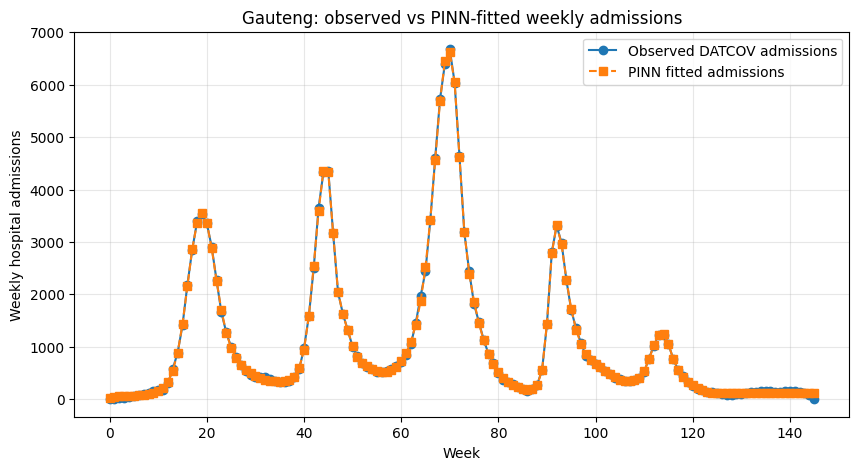

In [15]:
# ============================================================
# Adam fit
# ============================================================

# ------------------------------------------------------------
# Predict admissions directly
# Do NOT call compute_loss() inside torch.no_grad()
# ------------------------------------------------------------

with torch.no_grad():

    Y_mid = model(t_mid)

    I_mid = Y_mid[:, 2:3]

    eta = epi_params()["eta"]

    A_pred = N0 * eta * I_mid * 7.0

    A_pred_np = A_pred.cpu().numpy().flatten()
    A_obs_np = A_obs.cpu().numpy().flatten()


# ------------------------------------------------------------
# Fit metrics in actual admissions/week
# ------------------------------------------------------------

rmse = np.sqrt(
    np.mean((A_pred_np - A_obs_np)**2)
)

mae = np.mean(
    np.abs(A_pred_np - A_obs_np)
)

print(f"RMSE = {rmse:.2f} admissions/week")
print(f"MAE  = {mae:.2f} admissions/week")


# ------------------------------------------------------------
# Plot observed vs fitted admissions
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    data["t"],
    A_obs_np,
    "o-",
    label="Observed DATCOV admissions"
)

plt.plot(
    data["t"],
    A_pred_np,
    "s--",
    label="PINN fitted admissions"
)

plt.xlabel("Week")
plt.ylabel("Weekly hospital admissions")
plt.title("Gauteng: observed vs PINN-fitted weekly admissions")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [16]:
# ============================================================
# Inspect fitted states, parameters and beta(t)
# ============================================================

# Dense time grid over fitted period
t_plot = torch.linspace(
    0.0,
    T_days,
    1000
).reshape(-1, 1)

with torch.no_grad():

    # --------------------------------------------------------
    # Compartment trajectories
    # --------------------------------------------------------
    Y_plot = model(t_plot)

    S = Y_plot[:, 0].cpu().numpy()
    E = Y_plot[:, 1].cpu().numpy()
    I = Y_plot[:, 2].cpu().numpy()
    H = Y_plot[:, 3].cpu().numpy()
    R = Y_plot[:, 4].cpu().numpy()

    N_living = S + E + I + H + R

    # --------------------------------------------------------
    # beta(t)
    # --------------------------------------------------------
    beta_plot = beta_model(t_plot).cpu().numpy().flatten()

    # --------------------------------------------------------
    # Epidemiological parameters
    # --------------------------------------------------------
    pars = epi_params()

    print("Estimated epidemiological parameters:\n")

    for name, value in pars.items():
        print(
            f"{name:8s} = "
            f"{value.item():.6f} day^-1"
        )

   # --------------------------------------------------------
    # Fixed initial conditions
    # --------------------------------------------------------
    IC = Y0_target

    print("\nFixed initial conditions:\n")

    for name, value in zip(
        ["S0", "E0", "I0", "H0", "R0"],
        IC
    ):
        print(
            f"{name:3s} = {value.item():.10f}"
        )

    print(
        f"\nInitial total = "
        f"{IC.sum().item():.10f}"
    )

Estimated epidemiological parameters:

sigma    = 0.326377 day^-1
gamma    = 0.050607 day^-1
eta      = 0.053483 day^-1
gamma_H  = 0.059707 day^-1
d_I      = 0.000569 day^-1
d_H      = 0.001714 day^-1

Fixed initial conditions:

S0  = 0.9999999404
E0  = 0.0000000000
I0  = 0.0000000645
H0  = 0.0000000000
R0  = 0.0000000000

Initial total = 1.0000000000


In [17]:
# ============================================================
# Final Adam diagnostics BEFORE L-BFGS
# ============================================================

with torch.no_grad():

    # Weekly admissions
    Y_mid = model(t_mid)
    I_mid = Y_mid[:, 2:3]

    pars = epi_params()
    eta = pars["eta"]

    A_fit = N0 * eta * I_mid * 7.0

    obs = A_obs.cpu().numpy().flatten()
    pred = A_fit.cpu().numpy().flatten()

rmse = np.sqrt(np.mean((pred - obs)**2))
mae = np.mean(np.abs(pred - obs))

print("ADAM FIT DIAGNOSTICS")
print("--------------------")
print(f"RMSE = {rmse:.3f} admissions/week")
print(f"MAE  = {mae:.3f} admissions/week")

loss, ld, lp, lic, A_pred = compute_loss(
    lambda_physics=1e-2,
    lambda_IC=1.0
)

print(f"Total loss   = {loss.item():.6e}")
print(f"Data loss    = {ld.item():.6e}")
print(f"Physics loss = {lp.item():.6e}")
print(f"IC loss      = {lic.item():.6e}")

ADAM FIT DIAGNOSTICS
--------------------
RMSE = 26.715 admissions/week
MAE  = 19.879 admissions/week
Total loss   = 6.850006e-05
Data loss    = 2.854664e-05
Physics loss = 3.995343e-03
IC loss      = 0.000000e+00


## Full-data PINN: L-BFGS refinement and final results


In [18]:
# ============================================================
# L-BFGS refinement
# ============================================================

trainable_parameters = (
    list(model.parameters())
    + list(epi_params.parameters())
    + list(beta_model.parameters())
)

optimizer_lbfgs = torch.optim.LBFGS(
    trainable_parameters,
    lr=1.0,
    max_iter=500,
    max_eval=625,
    tolerance_grad=1e-9,
    tolerance_change=1e-12,
    history_size=100,
    line_search_fn="strong_wolfe"
)

evaluation = [0]

def closure():

    optimizer_lbfgs.zero_grad()

    loss, L_data, L_physics, L_IC, _ = compute_loss(
        lambda_physics=1e-2,
        lambda_IC=1.0
    )

    loss.backward()

    evaluation[0] += 1

    if evaluation[0] % 50 == 0:
        print(
            f"Evaluation {evaluation[0]:4d} | "
            f"Loss {loss.item():.6e} | "
            f"Data {L_data.item():.6e} | "
            f"Physics {L_physics.item():.6e} | "
            f"IC {L_IC.item():.6e}"
        )

    return loss


print("Starting L-BFGS refinement...\n")

optimizer_lbfgs.step(closure)

print(f"\nL-BFGS refinement complete.")
print(f"Function evaluations: {evaluation[0]}")

loss, ld, lp, lic, _ = compute_loss(
    lambda_physics=1e-2,
    lambda_IC=1.0
)

print(f"Final total loss   = {loss.item():.6e}")
print(f"Final data loss    = {ld.item():.6e}")
print(f"Final physics loss = {lp.item():.6e}")
print(f"Final IC loss      = {lic.item():.6e}")

Starting L-BFGS refinement...

Evaluation   50 | Loss 5.863938e-05 | Data 2.815623e-05 | Physics 3.048315e-03 | IC 0.000000e+00
Evaluation  100 | Loss 5.111829e-05 | Data 2.581866e-05 | Physics 2.529963e-03 | IC 0.000000e+00
Evaluation  150 | Loss 4.733307e-05 | Data 2.480138e-05 | Physics 2.253168e-03 | IC 0.000000e+00
Evaluation  200 | Loss 4.464344e-05 | Data 2.311402e-05 | Physics 2.152942e-03 | IC 0.000000e+00
Evaluation  250 | Loss 4.283716e-05 | Data 2.248177e-05 | Physics 2.035540e-03 | IC 0.000000e+00
Evaluation  300 | Loss 4.128709e-05 | Data 2.173883e-05 | Physics 1.954826e-03 | IC 0.000000e+00
Evaluation  350 | Loss 4.012884e-05 | Data 2.121316e-05 | Physics 1.891568e-03 | IC 0.000000e+00
Evaluation  400 | Loss 3.874025e-05 | Data 2.049243e-05 | Physics 1.824782e-03 | IC 0.000000e+00
Evaluation  450 | Loss 3.760466e-05 | Data 1.993666e-05 | Physics 1.766800e-03 | IC 0.000000e+00
Evaluation  500 | Loss 3.626505e-05 | Data 1.929564e-05 | Physics 1.696941e-03 | IC 0.000000e+00

POST L-BFGS FIT DIAGNOSTICS
--------------------------------
RMSE = 21.768 admissions/week
MAE  = 15.809 admissions/week

LOSS COMPONENTS
--------------------------------
Data loss    = 1.895356e-05
Physics loss = 1.683850e-03
IC loss      = 0.000000e+00
Total loss   = 3.579206e-05

PHYSICAL CONSISTENCY
--------------------------------
Number of decreases in R: 0
Minimum change in R: 1.6031300447139074e-06
Number of increases in living population: 0
Maximum change in living population: -1.043081283569336e-05
Minimum compartment value: 0.0

FINAL FITTED PARAMETERS
--------------------------------
sigma    = 0.326432 day^-1
gamma    = 0.050545 day^-1
eta      = 0.099623 day^-1
gamma_H  = 0.037226 day^-1
d_I      = 0.000551 day^-1
d_H      = 0.001702 day^-1


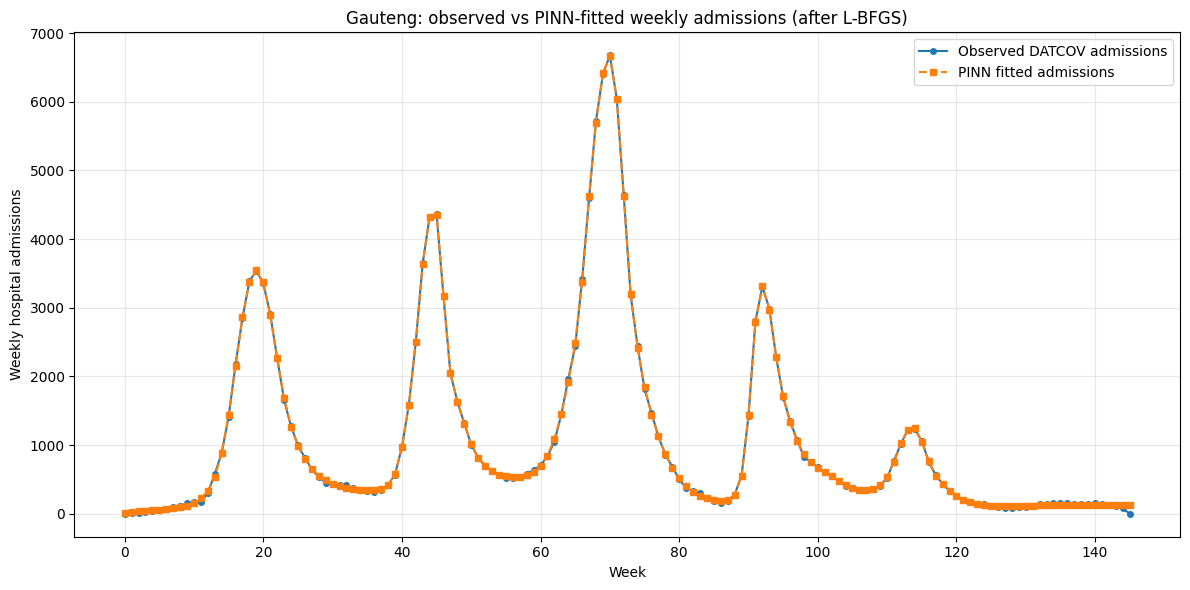

In [19]:
# ============================================================
# POST L-BFGS FINAL DIAGNOSTICS
# ============================================================

# ------------------------------------------------------------
# 1. Admissions fit
# ------------------------------------------------------------

with torch.no_grad():

    Y_mid = model(t_mid)
    I_mid = Y_mid[:, 2:3]

    pars = epi_params()
    eta = pars["eta"]

    A_fit = N0 * eta * I_mid * 7.0

    obs = A_obs.cpu().numpy().flatten()
    pred = A_fit.cpu().numpy().flatten()


rmse_lbfgs = np.sqrt(np.mean((pred - obs)**2))
mae_lbfgs = np.mean(np.abs(pred - obs))

print("POST L-BFGS FIT DIAGNOSTICS")
print("--------------------------------")

print(f"RMSE = {rmse_lbfgs:.3f} admissions/week")
print(f"MAE  = {mae_lbfgs:.3f} admissions/week")


# ------------------------------------------------------------
# 2. Loss components
# ------------------------------------------------------------

loss, L_data, L_physics, L_IC, _ = compute_loss(
    lambda_physics=0.01,
    lambda_IC=1.0
)

print("\nLOSS COMPONENTS")
print("--------------------------------")

print(f"Data loss    = {L_data.item():.6e}")
print(f"Physics loss = {L_physics.item():.6e}")
print(f"IC loss      = {L_IC.item():.6e}")
print(f"Total loss   = {loss.item():.6e}")


# ------------------------------------------------------------
# 3. Physical consistency
# ------------------------------------------------------------

t_check = torch.linspace(
    0.0,
    T_days,
    1000
).reshape(-1, 1)

with torch.no_grad():

    Y_check = model(t_check)

    R_check = Y_check[:, 4]

    N_check = torch.sum(
        Y_check,
        dim=1
    )

    dR = R_check[1:] - R_check[:-1]
    dN = N_check[1:] - N_check[:-1]


print("\nPHYSICAL CONSISTENCY")
print("--------------------------------")

print(
    "Number of decreases in R:",
    torch.sum(dR < -1e-8).item()
)

print(
    "Minimum change in R:",
    dR.min().item()
)

print(
    "Number of increases in living population:",
    torch.sum(dN > 1e-8).item()
)

print(
    "Maximum change in living population:",
    dN.max().item()
)

print(
    "Minimum compartment value:",
    Y_check.min().item()
)


# ------------------------------------------------------------
# 4. Final epidemiological parameters
# ------------------------------------------------------------

print("\nFINAL FITTED PARAMETERS")
print("--------------------------------")

for name, value in epi_params().items():

    print(
        f"{name:8s} = "
        f"{value.item():.6f} day^-1"
    )


# ------------------------------------------------------------
# 5. Admissions plot
# ------------------------------------------------------------

weeks = np.arange(len(obs))

plt.figure(figsize=(12, 6))

plt.plot(
    weeks,
    obs,
    marker="o",
    markersize=4,
    label="Observed DATCOV admissions"
)

plt.plot(
    weeks,
    pred,
    linestyle="--",
    marker="s",
    markersize=4,
    label="PINN fitted admissions"
)

plt.xlabel("Week")
plt.ylabel("Weekly hospital admissions")

plt.title(
    "Gauteng: observed vs PINN-fitted weekly admissions "
    "(after L-BFGS)"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

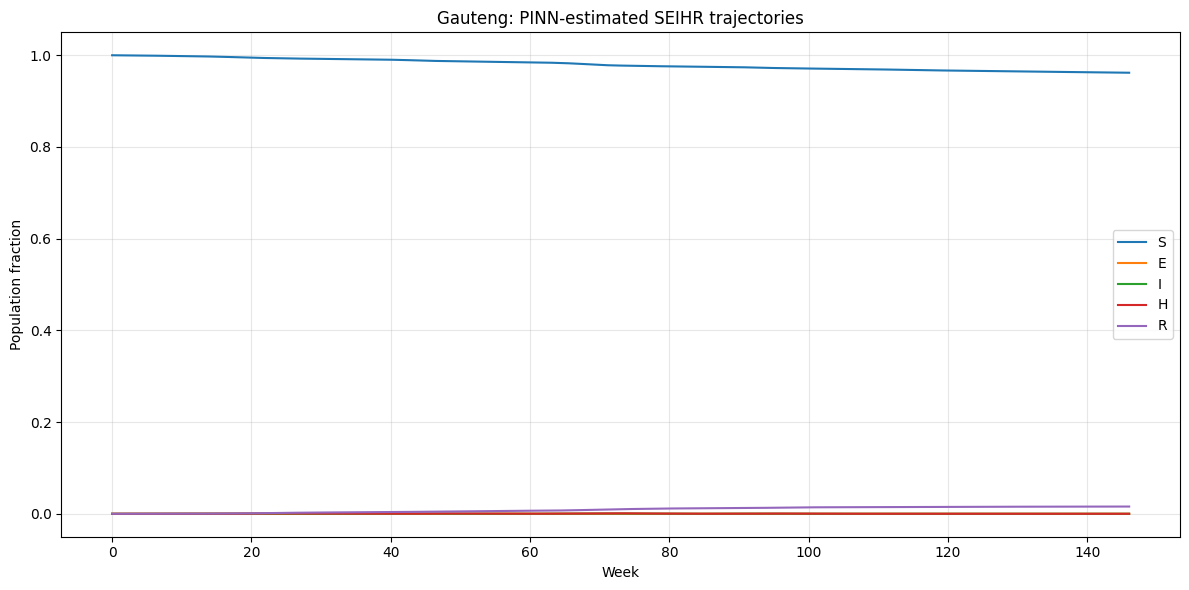

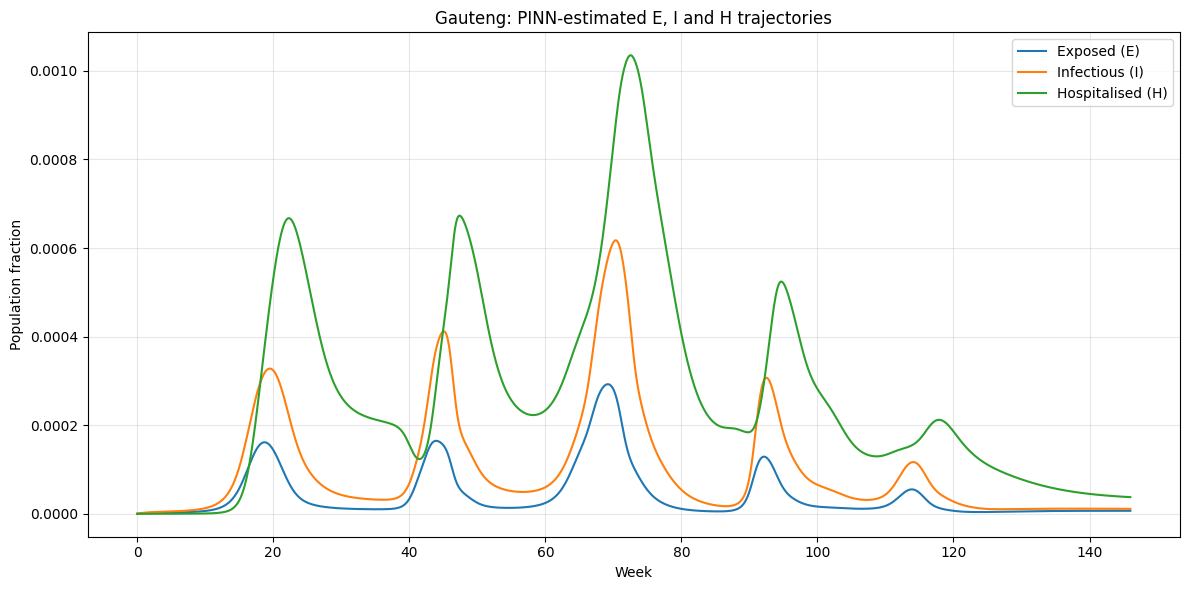

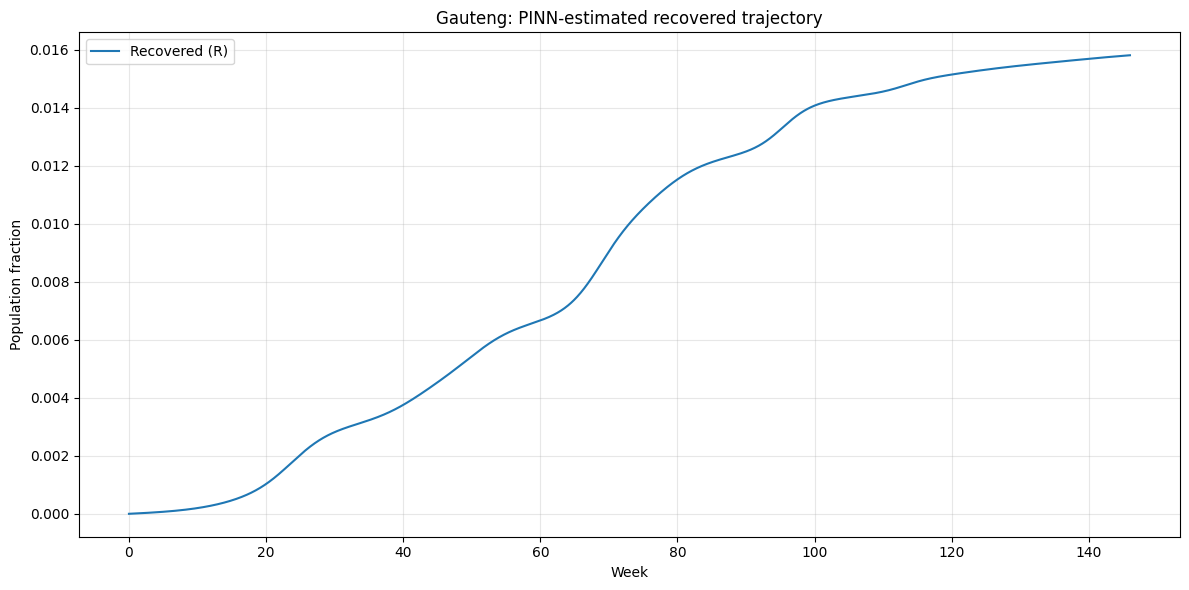

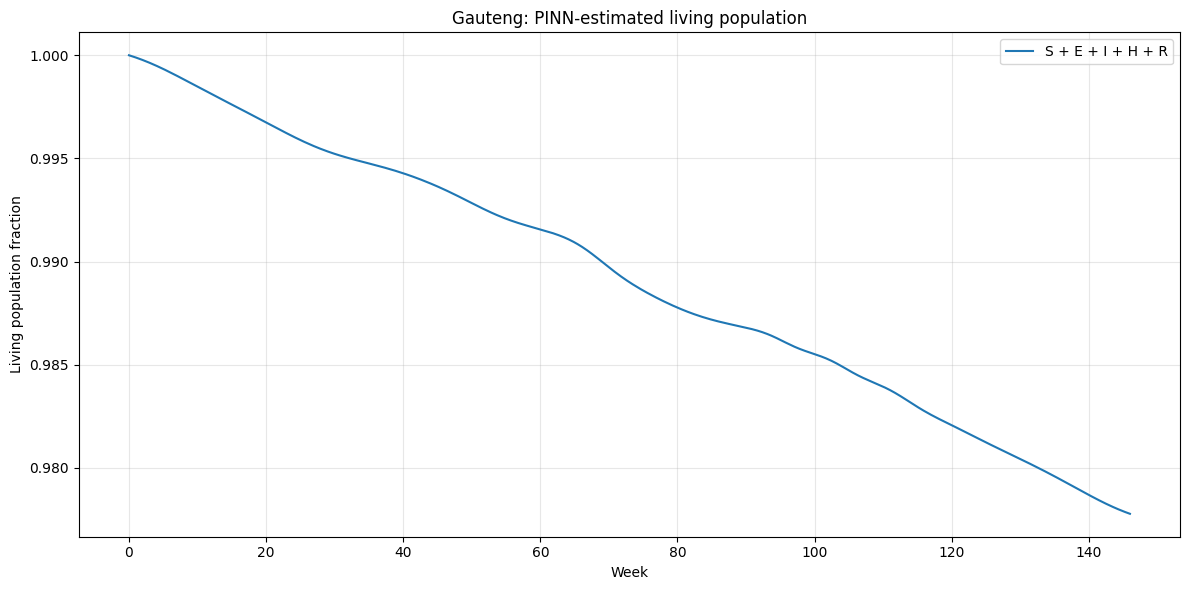

PHYSICAL DYNAMICS CHECK
--------------------------------
Number of decreases in R: 0
Number of increases in living population: 0
Initial susceptible fraction: 0.99999994
Final susceptible fraction:   0.96190721
Final recovered fraction:     0.01580985
Final living fraction:        0.97777259

GLOBAL COMPARTMENT PEAKS
--------------------------------
E peak: week 69.17 | fraction = 2.925108e-04
I peak: week 70.33 | fraction = 6.173110e-04
H peak: week 72.53 | fraction = 1.035100e-03


In [40]:
# ============================================================
# SEIHR DYNAMICS
# ============================================================

# Dense time grid
t_dyn = torch.linspace(
    0.0,
    T_days,
    2000
).reshape(-1, 1)

weeks_dyn = t_dyn.numpy().flatten() / 7.0


# ------------------------------------------------------------
# Evaluate final model
# ------------------------------------------------------------

with torch.no_grad():

    Y_dyn = model(t_dyn).cpu().numpy()

S_dyn = Y_dyn[:, 0]
E_dyn = Y_dyn[:, 1]
I_dyn = Y_dyn[:, 2]
H_dyn = Y_dyn[:, 3]
R_dyn = Y_dyn[:, 4]

N_dyn = (
    S_dyn
    + E_dyn
    + I_dyn
    + H_dyn
    + R_dyn
)


# ============================================================
# FIGURE 1: Full SEIHR trajectories
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(weeks_dyn, S_dyn, label="S")
plt.plot(weeks_dyn, E_dyn, label="E")
plt.plot(weeks_dyn, I_dyn, label="I")
plt.plot(weeks_dyn, H_dyn, label="H")
plt.plot(weeks_dyn, R_dyn, label="R")

plt.xlabel("Week")
plt.ylabel("Population fraction")

plt.title(
    "Gauteng: PINN-estimated SEIHR trajectories"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 2: Zoomed latent epidemic states E, I and H
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    weeks_dyn,
    E_dyn,
    label="Exposed (E)"
)

plt.plot(
    weeks_dyn,
    I_dyn,
    label="Infectious (I)"
)

plt.plot(
    weeks_dyn,
    H_dyn,
    label="Hospitalised (H)"
)

plt.xlabel("Week")
plt.ylabel("Population fraction")

plt.title(
    "Gauteng: PINN-estimated E, I and H trajectories"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 3: Recovered population
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    weeks_dyn,
    R_dyn,
    label="Recovered (R)"
)

plt.xlabel("Week")
plt.ylabel("Population fraction")

plt.title(
    "Gauteng: PINN-estimated recovered trajectory"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 4: Living population
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    weeks_dyn,
    N_dyn,
    label="S + E + I + H + R"
)

plt.xlabel("Week")
plt.ylabel("Living population fraction")

plt.title(
    "Gauteng: PINN-estimated living population"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# ============================================================
# NUMERICAL PHYSICAL CHECKS
# ============================================================

dR = np.diff(R_dyn)
dN = np.diff(N_dyn)

print("PHYSICAL DYNAMICS CHECK")
print("--------------------------------")

print(
    "Number of decreases in R:",
    np.sum(dR < -1e-8)
)

print(
    "Number of increases in living population:",
    np.sum(dN > 1e-8)
)

print(
    f"Initial susceptible fraction: {S_dyn[0]:.8f}"
)

print(
    f"Final susceptible fraction:   {S_dyn[-1]:.8f}"
)

print(
    f"Final recovered fraction:     {R_dyn[-1]:.8f}"
)

print(
    f"Final living fraction:        {N_dyn[-1]:.8f}"
)


# ============================================================
# GLOBAL PEAKS
# ============================================================

E_peak = np.argmax(E_dyn)
I_peak = np.argmax(I_dyn)
H_peak = np.argmax(H_dyn)

print("\nGLOBAL COMPARTMENT PEAKS")
print("--------------------------------")

print(
    f"E peak: week {weeks_dyn[E_peak]:.2f} | "
    f"fraction = {E_dyn[E_peak]:.6e}"
)

print(
    f"I peak: week {weeks_dyn[I_peak]:.2f} | "
    f"fraction = {I_dyn[I_peak]:.6e}"
)

print(
    f"H peak: week {weeks_dyn[H_peak]:.2f} | "
    f"fraction = {H_dyn[H_peak]:.6e}"
)

# **Final B(t)**

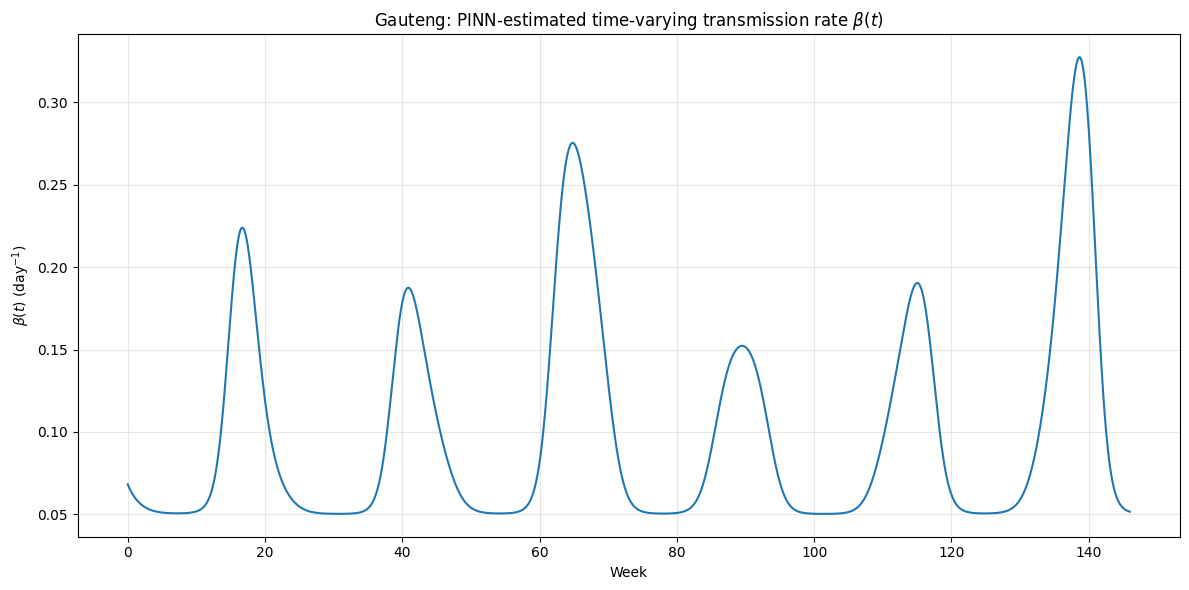

FINAL BETA(t) SUMMARY
--------------------------------
Minimum beta(t): 0.050194 day^-1
Maximum beta(t): 0.327487 day^-1
Mean beta(t):    0.099848 day^-1


In [21]:
# ============================================================
# Time-varying transmission rate beta(t)
# ============================================================

t_beta = torch.linspace(
    0.0,
    T_days,
    2000
).reshape(-1, 1)

weeks_beta = (
    t_beta.cpu().numpy().flatten() / 7.0
)

with torch.no_grad():

    beta_final = (
        beta_model(t_beta)
        .cpu()
        .numpy()
        .flatten()
    )


# ------------------------------------------------------------
# Plot beta(t)
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    weeks_beta,
    beta_final
)

plt.xlabel("Week")
plt.ylabel(r"$\beta(t)$ (day$^{-1}$)")

plt.title(
    r"Gauteng: PINN-estimated time-varying transmission rate $\beta(t)$"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("FINAL BETA(t) SUMMARY")
print("--------------------------------")

print(
    f"Minimum beta(t): "
    f"{beta_final.min():.6f} day^-1"
)

print(
    f"Maximum beta(t): "
    f"{beta_final.max():.6f} day^-1"
)

print(
    f"Mean beta(t):    "
    f"{beta_final.mean():.6f} day^-1"
)

In [22]:
# ============================================================
# FINAL LEARNED beta(t) PARAMETERS
# ============================================================

with torch.no_grad():

    # Directly learned coefficients
    a0 = beta_model.a0.item()
    a1 = beta_model.a1.item()
    a2 = beta_model.a2.item()
    a3 = beta_model.a3.item()

    # Convert raw frequency parameters to actual frequencies
    w1 = beta_model.bounded(
        beta_model.raw_w1,
        2*np.pi/500.0,
        2*np.pi/180.0
    ).item()

    w2 = beta_model.bounded(
        beta_model.raw_w2,
        2*np.pi/250.0,
        2*np.pi/90.0
    ).item()

    w3 = beta_model.bounded(
        beta_model.raw_w3,
        2*np.pi/150.0,
        2*np.pi/45.0
    ).item()

    # Convert raw phase parameters to actual phases
    phi1 = beta_model.bounded(
        beta_model.raw_phi1,
        0.0,
        2*np.pi
    ).item()

    phi2 = beta_model.bounded(
        beta_model.raw_phi2,
        0.0,
        2*np.pi
    ).item()

    phi3 = beta_model.bounded(
        beta_model.raw_phi3,
        0.0,
        2*np.pi
    ).item()

    # Corresponding periods in days
    T1 = 2*np.pi / w1
    T2 = 2*np.pi / w2
    T3 = 2*np.pi / w3


print("FINAL LEARNED beta(t) PARAMETERS")
print("--------------------------------")

print(f"a0 = {a0:.6f}")
print(f"a1 = {a1:.6f}")
print(f"a2 = {a2:.6f}")
print(f"a3 = {a3:.6f}")

print("\nAngular frequencies:")
print(f"w1 = {w1:.6f} rad/day")
print(f"w2 = {w2:.6f} rad/day")
print(f"w3 = {w3:.6f} rad/day")

print("\nCorresponding periods:")
print(f"T1 = {T1:.2f} days = {T1/7:.2f} weeks")
print(f"T2 = {T2:.2f} days = {T2/7:.2f} weeks")
print(f"T3 = {T3:.2f} days = {T3/7:.2f} weeks")

print("\nPhase shifts:")
print(f"phi1 = {phi1:.6f} rad")
print(f"phi2 = {phi2:.6f} rad")
print(f"phi3 = {phi3:.6f} rad")

FINAL LEARNED beta(t) PARAMETERS
--------------------------------
a0 = -4.617471
a1 = -0.517381
a2 = -3.089592
a3 = 0.483700

Angular frequencies:
w1 = 0.012745 rad/day
w2 = 0.037574 rad/day
w3 = 0.077897 rad/day

Corresponding periods:
T1 = 492.99 days = 70.43 weeks
T2 = 167.22 days = 23.89 weeks
T3 = 80.66 days = 11.52 weeks

Phase shifts:
phi1 = 5.227414 rad
phi2 = 6.252905 rad
phi3 = 6.156129 rad


# **Forecasting**

# Forecast PINN: 100-week training, 46-week forecast


In [23]:
# ============================================================
# FORECAST PINN: TRAINING-ONLY PHYSICS GRID
# ============================================================

# First 100 weeks are used for training.
# Weeks 100–145 are held out for forecast evaluation.

forecast_train_weeks = 100
forecast_train_end_days = 7.0 * forecast_train_weeks

# Physics is enforced ONLY within the training period.
t_physics_forecast = torch.linspace(
    0.0,
    forecast_train_end_days,
    500
).reshape(-1, 1)

t_physics_forecast.requires_grad_(True)

print("Forecast physics training interval:")
print(f"0 to {forecast_train_end_days:.0f} days")
print(f"Number of collocation points: {len(t_physics_forecast)}")

Forecast physics training interval:
0 to 700 days
Number of collocation points: 500


In [24]:
# ============================================================
# FORECAST PINN: SCALED LOSS FUNCTION
# ============================================================

def compute_forecast_loss(lambda_physics=1e-2, lambda_IC=1.0):

    # 1. Data loss — first 100 weeks only
    Y_mid = forecast_model(t_mid_train)

    I_mid = Y_mid[:, 2:3]
    eta = forecast_epi_params()["eta"]

    A_pred = 7.0 * N0 * eta * I_mid

    L_data = torch.mean(
        ((A_pred / 5000.0) - (A_train / 5000.0)) ** 2
    )

    # 2. Scaled physics loss
    fS, fE, fI, fH, fR = forecast_physics_residuals(
        t_physics_forecast
    )

    physics_scale = 1e-4

    L_physics = (
        torch.mean((fS / physics_scale) ** 2)
        + torch.mean((fE / physics_scale) ** 2)
        + torch.mean((fI / physics_scale) ** 2)
        + torch.mean((fH / physics_scale) ** 2)
        + torch.mean((fR / physics_scale) ** 2)
    ) / 5.0

    # 3. Initial condition loss
    t0 = torch.zeros(
        (1, 1),
        dtype=t_mid_train.dtype,
        device=t_mid_train.device
    )

    Y0_pred = forecast_model(t0).reshape(-1)

    L_IC = torch.mean(
        (Y0_pred - Y0_target) ** 2
    )

    # 4. Total loss
    total_loss = (
        L_data
        + lambda_physics * L_physics
        + lambda_IC * L_IC
    )

    return total_loss, L_data, L_physics, L_IC, A_pred


print("Forecast physics residuals and scaled loss successfully defined.")

Forecast physics residuals and scaled loss successfully defined.


In [25]:
# ============================================================
# 100-WEEK TRAINING / 46-WEEK FORECAST
# ============================================================

n_weeks = len(data)          # 146 weeks
train_end = 100
forecast_horizon = n_weeks - train_end

# Training observations: weeks 0–99
A_train = A_obs[:train_end].clone()
t_mid_train = t_mid[:train_end].clone()

# Test observations: weeks 100–145
A_test = A_obs[train_end:].clone()
t_mid_test = t_mid[train_end:].clone()

print(f"Total weeks: {n_weeks}")
print(f"Training weeks: {train_end}")
print(f"Forecast weeks: {forecast_horizon}")
print(f"Training observations: {len(A_train)}")
print(f"Test observations: {len(A_test)}")

Total weeks: 146
Training weeks: 100
Forecast weeks: 46
Training observations: 100
Test observations: 46


In [26]:
# ============================================================
# INITIALISE FRESH FORECAST MODEL
# Training-only physics grid: days 0–700
# ============================================================

# Set seeds for reproducibility
import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Initialise fresh forecast models
forecast_model = SEIHR_PINN().float()
forecast_epi_params = EpidemiologicalParameters().float()
forecast_beta_model = TimeVaryingBeta().float()

# Ensure training tensors use float32
A_train = A_train.float()
t_mid_train = t_mid_train.float()
t_physics_forecast = (
    t_physics_forecast.detach()
    .float()
    .requires_grad_(True)
)
Y0_target = Y0_target.float()

# Collect trainable parameters
forecast_trainable_parameters = (
    list(forecast_model.parameters())
    + list(forecast_epi_params.parameters())
    + list(forecast_beta_model.parameters())
)

print("Fresh forecast PINN initialised successfully.")
print(f"Training observations: {len(A_train)} weeks")
print(f"Held-out observations: {len(A_test)} weeks")
print(f"Physics training interval: 0–{forecast_train_end_days:.0f} days")
print(
    f"Trainable parameters: "
    f"{sum(p.numel() for p in forecast_trainable_parameters):,}"
)

Fresh forecast PINN initialised successfully.
Training observations: 100 weeks
Held-out observations: 46 weeks
Physics training interval: 0–700 days
Trainable parameters: 12,951


In [27]:
# ============================================================
# FORECAST PINN: CORRECTED PHYSICS RESIDUALS
# ============================================================

def forecast_physics_residuals(t):

    t = t.detach().clone().requires_grad_(True)

    Y = forecast_model(t)

    S = Y[:, 0:1]
    E = Y[:, 1:2]
    I = Y[:, 2:3]
    H = Y[:, 3:4]
    R = Y[:, 4:5]

    p = forecast_epi_params()
    beta_t = forecast_beta_model(t)

    # Fixed natural mortality rate (per day)
    mu = 9.39 / (1000.0 * 365.0)

    N = S + E + I + H + R

    dSdt = gradient(S, t)
    dEdt = gradient(E, t)
    dIdt = gradient(I, t)
    dHdt = gradient(H, t)
    dRdt = gradient(R, t)

    infection = beta_t * S * I / (N + 1e-8)

    fS = dSdt + infection + mu * S

    fE = (
        dEdt
        - infection
        + (p["sigma"] + mu) * E
    )

    fI = (
        dIdt
        - p["sigma"] * E
        + (p["gamma"] + p["eta"] + p["d_I"] + mu) * I
    )

    fH = (
        dHdt
        - p["eta"] * I
        + (p["gamma_H"] + p["d_H"] + mu) * H
    )

    fR = (
        dRdt
        - p["gamma"] * I
        - p["gamma_H"] * H
        + mu * R
    )

    return fS, fE, fI, fH, fR

## Forecast PINN: training and refinement


In [28]:
# ============================================================
# ADAM TRAINING — FIRST 100 WEEKS
# TAKES 5 MINS TO RUN ROUGHLY
# ============================================================

forecast_model.train()
forecast_epi_params.train()
forecast_beta_model.train()

forecast_optimizer = torch.optim.Adam(
    forecast_trainable_parameters,
    lr=1e-3
)

# Adjusted weights for scaled physics loss
physics_weights = [1e-5, 1e-4, 1e-3, 1e-2]
epochs_per_stage = 2500

forecast_loss_history = []

for stage, lambda_physics in enumerate(physics_weights, start=1):

    print(
        f"\nStage {stage}/4 | "
        f"Physics weight = {lambda_physics}"
    )

    for epoch in range(1, epochs_per_stage + 1):

        forecast_optimizer.zero_grad()

        loss, L_data, L_physics, L_IC, _ = compute_forecast_loss(
            lambda_physics=lambda_physics,
            lambda_IC=1.0
        )

        loss.backward()
        forecast_optimizer.step()

        forecast_loss_history.append(loss.item())

        if epoch % 500 == 0:
            print(
                f"Epoch {epoch:4d}/{epochs_per_stage} | "
                f"Loss: {loss.item():.6e} | "
                f"Data: {L_data.item():.6e} | "
                f"Physics: {L_physics.item():.6e}"
            )

print("\nAdam training complete!")

# Evaluate training fit
forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

with torch.no_grad():

    Y_pred = forecast_model(t_mid_train)

    eta = forecast_epi_params()["eta"]

    A_pred_train = (
        7 * N0 * eta * Y_pred[:, 2:3]
    ).cpu().numpy().flatten()

A_actual_train = A_train.detach().cpu().numpy().flatten()

train_rmse = np.sqrt(
    np.mean((A_actual_train - A_pred_train)**2)
)

train_mae = np.mean(
    np.abs(A_actual_train - A_pred_train)
)

print(f"\nTraining RMSE: {train_rmse:.3f}")
print(f"Training MAE:  {train_mae:.3f}")


Stage 1/4 | Physics weight = 1e-05
Epoch  500/2500 | Loss: 7.190244e-03 | Data: 7.181551e-03 | Physics: 8.692634e-01
Epoch 1000/2500 | Loss: 5.699935e-03 | Data: 5.696452e-03 | Physics: 3.483050e-01
Epoch 1500/2500 | Loss: 2.928046e-03 | Data: 2.925533e-03 | Physics: 2.512621e-01
Epoch 2000/2500 | Loss: 1.920283e-03 | Data: 1.918780e-03 | Physics: 1.503852e-01
Epoch 2500/2500 | Loss: 1.239386e-03 | Data: 1.238095e-03 | Physics: 1.290946e-01

Stage 2/4 | Physics weight = 0.0001
Epoch  500/2500 | Loss: 9.431325e-04 | Data: 9.369595e-04 | Physics: 6.173062e-02
Epoch 1000/2500 | Loss: 4.904183e-04 | Data: 4.859016e-04 | Physics: 4.516741e-02
Epoch 1500/2500 | Loss: 4.488900e-04 | Data: 4.450095e-04 | Physics: 3.880507e-02
Epoch 2000/2500 | Loss: 4.209427e-04 | Data: 4.176653e-04 | Physics: 3.277442e-02
Epoch 2500/2500 | Loss: 2.847470e-04 | Data: 2.821438e-04 | Physics: 2.603285e-02

Stage 3/4 | Physics weight = 0.001
Epoch  500/2500 | Loss: 3.164648e-04 | Data: 2.988314e-04 | Physics: 1.

In [29]:
# ============================================================
# 100 WEEK MODEL: L-BFGS REFINEMENT
# ============================================================

import copy

# Save Adam-trained weights
adam_checkpoint = {
    "model": copy.deepcopy(forecast_model.state_dict()),
    "epi": copy.deepcopy(forecast_epi_params.state_dict()),
    "beta": copy.deepcopy(forecast_beta_model.state_dict())
}

# Collect trainable parameters
forecast_trainable_parameters = (
    list(forecast_model.parameters())
    + list(forecast_epi_params.parameters())
    + list(forecast_beta_model.parameters())
)

# Same L-BFGS settings as original model
forecast_lbfgs = torch.optim.LBFGS(
    forecast_trainable_parameters,
    lr=1.0,
    max_iter=500,
    max_eval=625,
    tolerance_grad=1e-9,
    tolerance_change=1e-12,
    history_size=100,
    line_search_fn="strong_wolfe"
)

lambda_physics_final = 1e-2
evaluation = [0]

def forecast_closure():

    forecast_lbfgs.zero_grad()

    loss, L_data, L_physics, L_IC, _ = compute_forecast_loss(
        lambda_physics=lambda_physics_final,
        lambda_IC=1.0
    )

    loss.backward()
    evaluation[0] += 1

    if evaluation[0] % 50 == 0:
        print(
            f"Evaluation {evaluation[0]} | "
            f"Loss {loss.item():.8e} | "
            f"Data {L_data.item():.8e} | "
            f"Physics {L_physics.item():.8e}"
        )

    return loss


# Loss before refinement
initial_loss = compute_forecast_loss(
    lambda_physics=lambda_physics_final,
    lambda_IC=1.0
)[0].item()

print(f"Initial loss: {initial_loss:.12e}")
print("Starting L-BFGS refinement...\n")

# Run L-BFGS
forecast_lbfgs.step(forecast_closure)

# Loss after refinement
final_loss = compute_forecast_loss(
    lambda_physics=lambda_physics_final,
    lambda_IC=1.0
)[0].item()

state = forecast_lbfgs.state[forecast_trainable_parameters[0]]

print("\nL-BFGS complete.")
print("Iterations:", state.get("n_iter"))
print("Function evaluations:", evaluation[0])
print(f"Initial loss: {initial_loss:.12e}")
print(f"Final loss:   {final_loss:.12e}")

# Evaluate final training accuracy
forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

with torch.no_grad():
    Y_train = forecast_model(t_mid_train)
    eta = forecast_epi_params()["eta"]

    A_pred_train = (
        7 * N0 * eta * Y_train[:, 2:3]
    ).cpu().numpy().flatten()

A_actual_train = A_train.detach().cpu().numpy().flatten()

train_rmse = np.sqrt(
    np.mean((A_actual_train - A_pred_train) ** 2)
)

train_mae = np.mean(
    np.abs(A_actual_train - A_pred_train)
)

print(f"\nFinal training RMSE: {train_rmse:.3f}")
print(f"Final training MAE:  {train_mae:.3f}")

Initial loss: 2.149700885639e-04
Starting L-BFGS refinement...

Evaluation 50 | Loss 1.20567784e-04 | Data 6.03707776e-05 | Physics 6.01970125e-03
Evaluation 100 | Loss 1.13756570e-04 | Data 5.62359019e-05 | Physics 5.75206662e-03
Evaluation 150 | Loss 1.09053814e-04 | Data 5.34130595e-05 | Physics 5.56407543e-03
Evaluation 200 | Loss 1.00280391e-04 | Data 4.96934153e-05 | Physics 5.05869742e-03
Evaluation 250 | Loss 9.32579132e-05 | Data 4.68103644e-05 | Physics 4.64475481e-03
Evaluation 300 | Loss 8.80847656e-05 | Data 4.51546948e-05 | Physics 4.29300684e-03
Evaluation 350 | Loss 8.52313824e-05 | Data 4.32591041e-05 | Physics 4.19722777e-03
Evaluation 400 | Loss 7.97577668e-05 | Data 4.02889964e-05 | Physics 3.94687662e-03
Evaluation 450 | Loss 7.63353455e-05 | Data 3.71422866e-05 | Physics 3.91930621e-03
Evaluation 500 | Loss 7.28108571e-05 | Data 3.41831255e-05 | Physics 3.86277330e-03

L-BFGS complete.
Iterations: 500
Function evaluations: 533
Initial loss: 2.149700885639e-04
Fina

## 8. Forecast PINN: evaluation and baselines


Training observations: 100
Verified training RMSE: 28.449
Verified training MAE:  20.781


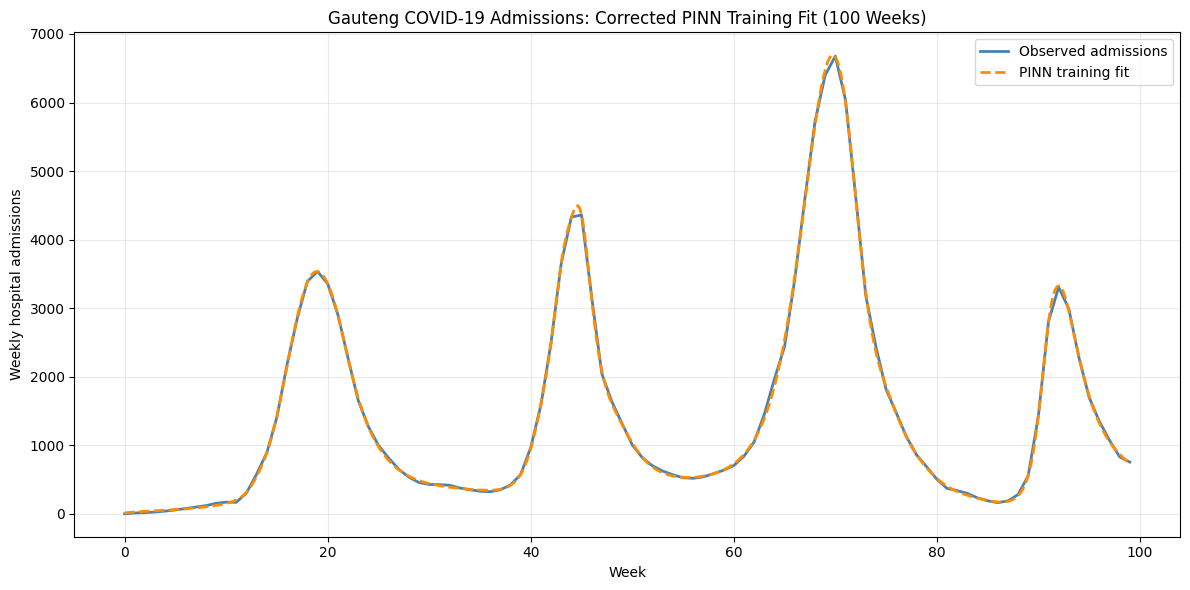

In [30]:

# ============================================================
# FINAL 100-WEEK TRAINING GRAPH
# ============================================================


forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

dtype = next(forecast_model.parameters()).dtype
device = next(forecast_model.parameters()).device

# Predictions at actual training observations
with torch.no_grad():
    eta = forecast_epi_params()["eta"]

    predicted = (
        7.0 * N0 * eta *
        forecast_model(t_mid_train)[:, 2:3]
    ).cpu().numpy().flatten()

actual = A_train.detach().cpu().numpy().flatten()

rmse = np.sqrt(np.mean((actual - predicted)**2))
mae = np.mean(np.abs(actual - predicted))

print(f"Training observations: {len(actual)}")
print(f"Verified training RMSE: {rmse:.3f}")
print(f"Verified training MAE:  {mae:.3f}")

# Smooth predictions for plotting
weeks_smooth = np.linspace(0, 99, 500)

t_smooth = torch.tensor(
    (7.0 * weeks_smooth + 3.5).reshape(-1, 1),
    dtype=dtype,
    device=device
)

with torch.no_grad():
    smooth_predictions = (
        7.0 * N0 * eta *
        forecast_model(t_smooth)[:, 2:3]
    ).cpu().numpy().flatten()

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(12, 6))

# Observed admissions - solid blue
plt.plot(
    np.arange(100),
    actual,
    color="steelblue",
    linewidth=2,
    label="Observed admissions"
)

# PINN training fit - dashed orange
plt.plot(
    weeks_smooth,
    smooth_predictions,
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label="PINN training fit"
)

plt.xlabel("Week")
plt.ylabel("Weekly hospital admissions")
plt.title("Gauteng COVID-19 Admissions: Corrected PINN Training Fit (100 Weeks)")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

# Save high-resolution figure for thesis
import os
os.makedirs("Gauteng_PINN_Final_Results", exist_ok=True)

plt.savefig(
    "Gauteng_PINN_Final_Results/corrected_training_fit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [31]:
# ============================================================
#  46-WEEK OUT-OF-SAMPLE FORECAST
# ============================================================

forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

dtype = next(forecast_model.parameters()).dtype
device = next(forecast_model.parameters()).device

# Predict all 146 weeks using the trained model
t_all = t_mid.to(dtype=dtype, device=device)

with torch.no_grad():
    eta = forecast_epi_params()["eta"]

    A_pred_all = (
        7 * N0 * eta *
        forecast_model(t_all)[:, 2:3]
    ).cpu().numpy().flatten()

A_actual_all = A_obs.detach().cpu().numpy().flatten()

# Evaluate ONLY the unseen weeks 100–145
actual_test = A_actual_all[100:]
pred_test = A_pred_all[100:]

test_rmse = np.sqrt(np.mean((actual_test - pred_test)**2))
test_mae = np.mean(np.abs(actual_test - pred_test))

print(f"Forecast RMSE: {test_rmse:.3f}")
print(f"Forecast MAE:  {test_mae:.3f}")

# Smooth training predictions
weeks_train = np.linspace(0, 99, 500)

# Smooth forecast predictions
weeks_forecast = np.linspace(100, 145, 300)

def predict_admissions(weeks):

    times = torch.tensor(
        (7 * weeks + 3.5).reshape(-1, 1),
        dtype=dtype,
        device=device
    )

    with torch.no_grad():
        predictions = (
            7 * N0 * eta *
            forecast_model(times)[:, 2:3]
        )

    return predictions.cpu().numpy().flatten()


train_smooth = predict_admissions(weeks_train)
forecast_smooth = predict_admissions(weeks_forecast)



Forecast RMSE: 299.899
Forecast MAE:  164.051


In [32]:
# ============================================================
# FORECAST ACCURACY AND BASELINE COMPARISON
# ============================================================

actual_test = A_actual_all[100:146]
pred_test = A_pred_all[100:146]

forecast_rmse = np.sqrt(
    np.mean((actual_test - pred_test) ** 2)
)

forecast_mae = np.mean(
    np.abs(actual_test - pred_test)
)

# Simple baseline: predict the last observed training value
baseline_pred = np.full_like(
    actual_test,
    A_actual_all[99]
)

baseline_rmse = np.sqrt(
    np.mean((actual_test - baseline_pred) ** 2)
)

baseline_mae = np.mean(
    np.abs(actual_test - baseline_pred)
)

print("46-WEEK FORECAST EVALUATION")
print("---------------------------")
print(f"PINN RMSE:     {forecast_rmse:.3f}")
print(f"PINN MAE:      {forecast_mae:.3f}")
print(f"Baseline RMSE: {baseline_rmse:.3f}")
print(f"Baseline MAE:  {baseline_mae:.3f}")

46-WEEK FORECAST EVALUATION
---------------------------
PINN RMSE:     299.899
PINN MAE:      164.051
Baseline RMSE: 513.625
Baseline MAE:  475.724


In [33]:
# ============================================================
# FORECAST ACCURACY BY PERIOD
# ============================================================

forecast_horizons = [4, 8, 12, 24, 46]

print("FORECAST ACCURACY BY HORIZON")
print("-" * 68)
print(
    f"{'Weeks':<10}"
    f"{'PINN RMSE':<15}"
    f"{'PINN MAE':<15}"
    f"{'Baseline RMSE':<15}"
    f"{'Baseline MAE':<15}"
)
print("-" * 68)

for horizon in forecast_horizons:

    # First 'horizon' unseen weeks
    actual = A_actual_all[100:100 + horizon]
    predicted = A_pred_all[100:100 + horizon]

    # Constant forecast using last training observation
    baseline = np.full_like(actual, A_actual_all[99])

    # PINN accuracy
    pinn_rmse = np.sqrt(np.mean((actual - predicted)**2))
    pinn_mae = np.mean(np.abs(actual - predicted))

    # Baseline accuracy
    baseline_rmse = np.sqrt(np.mean((actual - baseline)**2))
    baseline_mae = np.mean(np.abs(actual - baseline))

    print(
        f"{horizon:<10}"
        f"{pinn_rmse:<15.3f}"
        f"{pinn_mae:<15.3f}"
        f"{baseline_rmse:<15.3f}"
        f"{baseline_mae:<15.3f}"
    )

FORECAST ACCURACY BY HORIZON
--------------------------------------------------------------------
Weeks     PINN RMSE      PINN MAE       Baseline RMSE  Baseline MAE   
--------------------------------------------------------------------
4         52.404         51.580         191.855        176.292        
8         39.212         34.452         304.068        280.136        
12        171.810        101.688        298.238        269.408        
24        408.909        254.911        368.290        330.387        
46        299.899        164.051        513.625        475.724        


## Supplementary exploratory physics diagnostics



In [34]:
# ============================================================
# FORECASTED PINN: PARAMETER ESTIMATES AND BETA(t)
# ============================================================

forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

with torch.no_grad():

    # Epidemiological parameter estimates
    parameters = forecast_epi_params()

    print("FORECAST PINN: ESTIMATED PARAMETERS")
    print("-----------------------------------")

    for name, value in parameters.items():
        print(f"{name:10s}: {value.item():.6f} per day")

    # Time-varying transmission rate across all 146 weeks
    beta_values = forecast_beta_model(t_mid).cpu().numpy().flatten()

    print("\nFORECAST PINN: BETA(t)")
    print("----------------------")
    print(f"Training beta minimum: {beta_values[:100].min():.6f}")
    print(f"Training beta maximum: {beta_values[:100].max():.6f}")
    print(f"Training beta mean:    {beta_values[:100].mean():.6f}")

    print(f"\nForecast beta minimum: {beta_values[100:].min():.6f}")
    print(f"Forecast beta maximum: {beta_values[100:].max():.6f}")
    print(f"Forecast beta mean:    {beta_values[100:].mean():.6f}")

    print("\nFIXED NATURAL MORTALITY")
    print("-----------------------")
    print(f"mu: {9.39 / (1000 * 365):.8f} per day")

FORECAST PINN: ESTIMATED PARAMETERS
-----------------------------------
sigma     : 0.329243 per day
gamma     : 0.050135 per day
eta       : 0.092182 per day
gamma_H   : 0.039452 per day
d_I       : 0.000189 per day
d_H       : 0.001116 per day

FORECAST PINN: BETA(t)
----------------------
Training beta minimum: 0.050233
Training beta maximum: 0.280799
Training beta mean:    0.085247

Forecast beta minimum: 0.050627
Forecast beta maximum: 0.221546
Forecast beta mean:    0.082492

FIXED NATURAL MORTALITY
-----------------------
mu: 0.00002573 per day


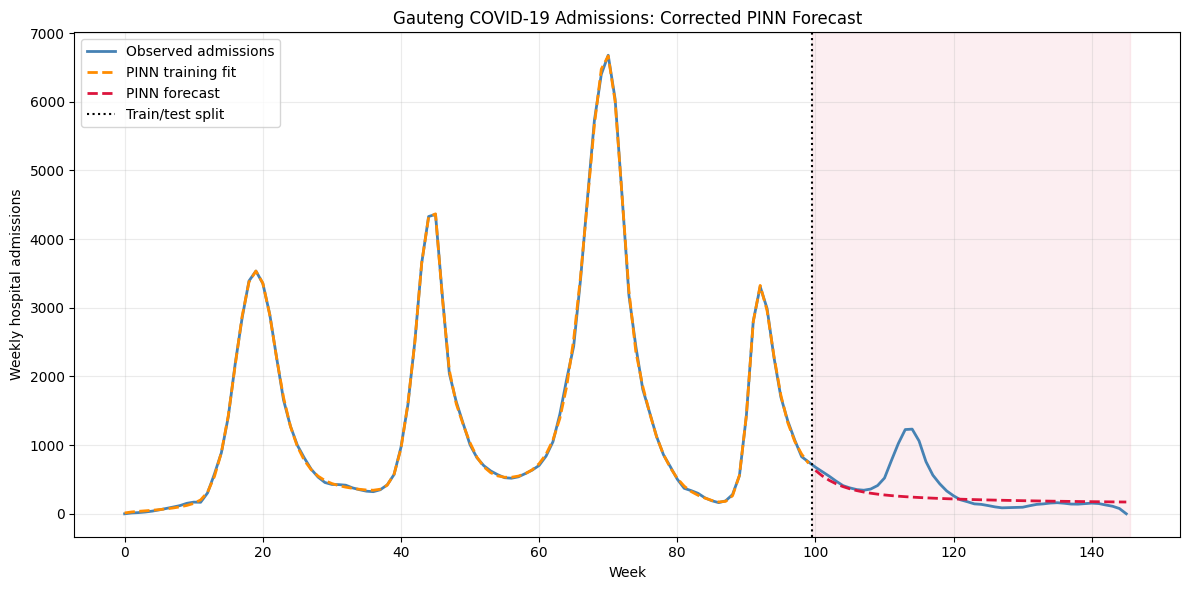

In [35]:
# ============================================================
# TRAINING AND FORECAST PLOT
# ============================================================

forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

# Generate predictions for all 146 weeks
with torch.no_grad():
    Y_all = forecast_model(t_mid)

    eta = forecast_epi_params()["eta"]

    A_pred_all = (
        7.0 * N0 * eta * Y_all[:, 2:3]
    ).cpu().numpy().flatten()

A_actual_all = A_obs.detach().cpu().numpy().flatten()

weeks = np.arange(len(A_actual_all))
train_end = 100

plt.figure(figsize=(12, 6))

# Observed hospital admissions
plt.plot(
    weeks,
    A_actual_all,
    color="steelblue",
    linewidth=2,
    label="Observed admissions"
)

# PINN training predictions
plt.plot(
    weeks[:train_end],
    A_pred_all[:train_end],
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label="PINN training fit"
)

# PINN held-out forecasts
plt.plot(
    weeks[train_end:],
    A_pred_all[train_end:],
    color="crimson",
    linewidth=2,
    linestyle="--",
    label="PINN forecast"
)

# Forecast period shading
plt.axvspan(
    train_end - 0.5,
    len(weeks) - 0.5,
    color="crimson",
    alpha=0.07
)

plt.axvline(
    train_end - 0.5,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Train/test split"
)

plt.xlabel("Week")
plt.ylabel("Weekly hospital admissions")
plt.title("Gauteng COVID-19 Admissions: Corrected PINN Forecast")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "Gauteng_PINN_Final_Results/corrected_forecast_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:

# ============================================================
# FINAL FORECAST METRICS AND BASELINE COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import torch
import os

forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

# Observed admissions
actual = A_obs.detach().cpu().numpy().flatten()

# Predictions from corrected forecast PINN
with torch.no_grad():
    eta = forecast_epi_params()["eta"]

    predicted = (
        7.0 * N0 * eta *
        forecast_model(t_mid)[:, 2:3]
    ).cpu().numpy().flatten()

train_end = 100
test_actual = actual[train_end:]
test_pred = predicted[train_end:]

# Baseline 1: last observed training value
persistence_value = actual[train_end - 1]
persistence_pred = np.full_like(test_actual, persistence_value)

# Baseline 2: mean of final 4 training weeks
four_week_mean = np.mean(actual[train_end - 4:train_end])
mean_baseline_pred = np.full_like(test_actual, four_week_mean)

def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    mae = np.mean(np.abs(y_true - y_pred))
    return rmse, mae

# Evaluate cumulative horizons from week 100
horizons = [4, 8, 12, 24, 46]
results = []

for h in horizons:
    row = {"Horizon (weeks)": h}

    for name, predictions in [
        ("PINN", test_pred),
        ("Persistence", persistence_pred),
        ("4-week mean", mean_baseline_pred)
    ]:
        rmse, mae = calculate_metrics(
            test_actual[:h],
            predictions[:h]
        )

        row[f"{name} RMSE"] = round(rmse, 3)
        row[f"{name} MAE"] = round(mae, 3)

    results.append(row)

metrics_df = pd.DataFrame(results)

print("FINAL CORRECTED FORECAST COMPARISON")
print("-----------------------------------")
print(f"Persistence value: {persistence_value:.3f}")
print(f"Four-week mean:    {four_week_mean:.3f}")
print(f"Test mean:         {test_actual.mean():.3f}")
print()
print(metrics_df.to_string(index=False))

# Save results
os.makedirs("Gauteng_PINN_Final_Results", exist_ok=True)

metrics_df.to_csv(
    "Gauteng_PINN_Final_Results/corrected_forecast_metrics.csv",
    index=False
)


FINAL CORRECTED FORECAST COMPARISON
-----------------------------------
Persistence value: 754.413
Four-week mean:    1002.617
Test mean:         346.224

 Horizon (weeks)  PINN RMSE   PINN MAE  Persistence RMSE  Persistence MAE  4-week mean RMSE  4-week mean MAE
               4  52.403999  51.580002        191.854996       176.292007        431.191010       424.496002
               8  39.212002  34.452000        304.067993       280.135986        541.408997       528.340027
              12 171.809998 101.688004        298.238007       269.407990        531.505005       514.007996
              24 408.908997 254.910995        368.290009       330.386993        544.969971       493.615997
              46 299.898987 164.050995        513.625000       475.723999        726.666016       679.593018


## Final thesis physics audits and transmission coefficients



In [37]:

# ============================================================
# FINAL CORRECTED FORECAST PINN: PHYSICS AUDIT
# ============================================================

import numpy as np
import pandas as pd
import torch
import os

forecast_model.eval()
forecast_epi_params.eval()
forecast_beta_model.eval()

# Separate training and held-out evaluation intervals
audit_grids = {
    "Training (days 0-700)": torch.linspace(
        0.0, 700.0, 300
    ).reshape(-1, 1),

    "Forecast (days 700-1022)": torch.linspace(
        700.0, float(T_days), 200
    ).reshape(-1, 1)
}

rows = []
names = ["S", "E", "I", "H", "R"]

for period, t in audit_grids.items():

    t = t.detach().clone().requires_grad_(True)

    # Residuals of the five SEIHR equations
    residuals = forecast_physics_residuals(t)

    # Calculate the corresponding ODE right-hand sides
    with torch.no_grad():
        Y = forecast_model(t)
        S, E, I, H, R = [
            Y[:, i:i+1] for i in range(5)
        ]

        p = forecast_epi_params()
        beta = forecast_beta_model(t)
        mu = 9.39 / (1000.0 * 365.0)

        N = S + E + I + H + R
        infection = beta * S * I / (N + 1e-8)

        rhs = [
            -infection - mu*S,
            infection - (p["sigma"] + mu)*E,
            p["sigma"]*E -
                (p["gamma"] + p["eta"] + p["d_I"] + mu)*I,
            p["eta"]*I -
                (p["gamma_H"] + p["d_H"] + mu)*H,
            p["gamma"]*I + p["gamma_H"]*H - mu*R
        ]

    for name, residual, flow in zip(names, residuals, rhs):

        residual_rms = torch.sqrt(
            torch.mean(residual.detach()**2)
        ).item()

        flow_rms = torch.sqrt(
            torch.mean(flow.detach()**2)
        ).item()

        relative = (
            100.0 * residual_rms / flow_rms
            if flow_rms > 1e-12 else np.nan
        )

        rows.append({
            "Period": period,
            "Equation": name,
            "Residual RMS": residual_rms,
            "Relative residual (%)": relative
        })

audit_df = pd.DataFrame(rows)

print("CORRECTED FORECAST PINN: PHYSICS AUDIT")
print("--------------------------------------")
print(audit_df.to_string(index=False, float_format="%.4f"))

os.makedirs("Gauteng_PINN_Final_Results", exist_ok=True)

audit_df.to_csv(
    "Gauteng_PINN_Final_Results/corrected_physics_audit.csv",
    index=False
)


CORRECTED FORECAST PINN: PHYSICS AUDIT
--------------------------------------
                  Period Equation  Residual RMS  Relative residual (%)
   Training (days 0-700)        S        0.0000                10.2517
   Training (days 0-700)        E        0.0000                89.9297
   Training (days 0-700)        I        0.0000                73.7048
   Training (days 0-700)        H        0.0000                54.9883
   Training (days 0-700)        R        0.0000                27.7138
Forecast (days 700-1022)        S        0.0000                20.9855
Forecast (days 700-1022)        E        0.0000               102.6488
Forecast (days 700-1022)        I        0.0000                87.0518
Forecast (days 700-1022)        H        0.0000                97.6927
Forecast (days 700-1022)        R        0.0000               101.1787


In [38]:

# ============================================================
# FORECAST PINN: LEARNED BETA(t) COEFFICIENTS
# ============================================================

forecast_beta_model.eval()

with torch.no_grad():

    b = forecast_beta_model

    a0 = b.a0.item()
    a1 = b.a1.item()
    a2 = b.a2.item()
    a3 = b.a3.item()

    w1 = b.bounded(
        b.raw_w1, 2*np.pi/500, 2*np.pi/180
    ).item()

    w2 = b.bounded(
        b.raw_w2, 2*np.pi/250, 2*np.pi/90
    ).item()

    w3 = b.bounded(
        b.raw_w3, 2*np.pi/150, 2*np.pi/45
    ).item()

    phi1 = b.bounded(b.raw_phi1, 0, 2*np.pi).item()
    phi2 = b.bounded(b.raw_phi2, 0, 2*np.pi).item()
    phi3 = b.bounded(b.raw_phi3, 0, 2*np.pi).item()

    print("100-WEEK FORECAST MODEL: BETA(t) COEFFICIENTS")
    print("------------------------------------------")

    for name, value in [
        ("a0", a0), ("a1", a1),
        ("a2", a2), ("a3", a3),
        ("w1", w1), ("w2", w2), ("w3", w3),
        ("phi1", phi1), ("phi2", phi2),
        ("phi3", phi3)
    ]:
        print(f"{name:5s} = {value:.6f}")

    print("\nOSCILLATION PERIODS")
    print(f"T1 = {2*np.pi/w1:.2f} days")
    print(f"T2 = {2*np.pi/w2:.2f} days")
    print(f"T3 = {2*np.pi/w3:.2f} days")


100-WEEK FORECAST MODEL: BETA(t) COEFFICIENTS
------------------------------------------
a0    = -4.779251
a1    = -2.301167
a2    = 1.274339
a3    = -0.250711
w1    = 0.019025
w2    = 0.050727
w3    = 0.096886
phi1  = 2.309260
phi2  = 3.172951
phi3  = 0.104054

OSCILLATION PERIODS
T1 = 330.25 days
T2 = 123.86 days
T3 = 64.85 days


In [39]:

# ============================================================
# FULL-DATA PINN: MATCHING PHYSICS AUDIT
# Same normalisation as corrected forecast audit
# ============================================================

import numpy as np
import pandas as pd
import torch

# Full-data PINN evaluation
t = torch.linspace(
    0.0, float(T_days), 500
).reshape(-1, 1)

t = t.detach().clone().requires_grad_(True)

# Residuals of the five SEIHR equations
residuals = physics_residuals(t)

# Evaluate the corresponding ODE right-hand sides
with torch.no_grad():

    Y = model(t)

    S, E, I, H, R = [
        Y[:, i:i+1] for i in range(5)
    ]

    p = epi_params()
    beta = beta_model(t)

    mu = 9.39 / (1000.0 * 365.0)

    N = S + E + I + H + R
    infection = beta * S * I / (N + 1e-8)

    rhs = [
        -infection - mu*S,
        infection - (p["sigma"] + mu)*E,
        p["sigma"]*E -
            (p["gamma"] + p["eta"] + p["d_I"] + mu)*I,
        p["eta"]*I -
            (p["gamma_H"] + p["d_H"] + mu)*H,
        p["gamma"]*I + p["gamma_H"]*H - mu*R
    ]

rows = []

for name, residual, flow in zip(
    ["S", "E", "I", "H", "R"],
    residuals,
    rhs
):

    residual_rms = torch.sqrt(
        torch.mean(residual.detach()**2)
    ).item()

    flow_rms = torch.sqrt(
        torch.mean(flow.detach()**2)
    ).item()

    relative = (
        100.0 * residual_rms / flow_rms
        if flow_rms > 1e-12 else np.nan
    )

    rows.append({
        "Equation": name,
        "Residual RMS": residual_rms,
        "Relative residual (%)": relative
    })

full_audit_df = pd.DataFrame(rows)

print("FULL-DATA PINN: MATCHING PHYSICS AUDIT")
print("-------------------------------------")
print(
    full_audit_df.to_string(
        index=False,
        float_format="%.6f"
    )
)


FULL-DATA PINN: MATCHING PHYSICS AUDIT
-------------------------------------
Equation  Residual RMS  Relative residual (%)
       S      0.000004              10.230750
       E      0.000003              76.461781
       I      0.000003              54.815283
       H      0.000004              42.369143
       R      0.000005              26.513399
